In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 한글 폰트 설정
from matplotlib import font_manager, rc

font_path = "C:/Windows/Fonts/malgun.ttf"
font = font_manager.FontProperties(fname=font_path).get_name()
rc('font', family=font)
plt.rcParams['axes.unicode_minus'] = False  # 마이너스 깨짐 방지

In [2]:
df = pd.read_csv('All.csv')

In [3]:
df

,Querylength,domain_token_count,path_token_count,avgdomaintokenlen,longdomaintokenlen,avgpathtokenlen,tld,charcompvowels,charcompace,ldl_url,...,SymbolCount_FileName,SymbolCount_Extension,SymbolCount_Afterpath,Entropy_URL,Entropy_Domain,Entropy_DirectoryName,Entropy_Filename,Entropy_Extension,Entropy_Afterpath,URL_Type_obf_Type
0,0,4,5,5.500000,14,4.400000,4,8,3,0,...,1,0,-1,0.726298,0.784493,0.894886,0.850608,NaN,-1.000000,Defacement
1,0,4,5,5.500000,14,6.000000,4,12,4,0,...,0,0,-1,0.688635,0.784493,0.814725,0.859793,0.000000,-1.000000,Defacement
2,0,4,5,5.500000,14,5.800000,4,12,5,0,...,0,0,-1,0.695049,0.784493,0.814725,0.801880,0.000000,-1.000000,Defacement
3,0,4,12,5.500000,14,5.500000,4,32,16,0,...,0,0,-1,0.640130,0.784493,0.814725,0.663210,0.000000,-1.000000,Defacement
4,0,4,6,5.500000,14,7.333334,4,18,11,0,...,0,0,-1,0.681307,0.784493,0.814725,0.804526,0.000000,-1.000000,Defacement
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
36702,29,4,14,5.750000,12,3.666667,4,20,24,3,...,3,2,7,0.690555,0.791265,0.777498,0.690227,0.656684,0.796205,spam
36703,0,4,13,3.750000,8,8.461538,4,24,23,0,...,16,15,-1,0.665492,0.820010,0.879588,0.674400,0.674671,-1.000000,spam
36704,58,3,27,6.666666,16,3.375000,3,41,34,20,...,8,7,9,0.656807,0.801139,0.684777,0.713622,0.717187,0.705245,spam
36705,35,3,13,4.333334,9,3.600000,3,15,13,7,...,9,8,3,0.725963,0.897617,0.871049,0.745932,0.758824,0.790772,spam


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 36707 entries, 0 to 36706
Data columns (total 80 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   Querylength                      36707 non-null  int64  
 1   domain_token_count               36707 non-null  int64  
 2   path_token_count                 36707 non-null  int64  
 3   avgdomaintokenlen                36707 non-null  float64
 4   longdomaintokenlen               36707 non-null  int64  
 5   avgpathtokenlen                  36427 non-null  float64
 6   tld                              36707 non-null  int64  
 7   charcompvowels                   36707 non-null  int64  
 8   charcompace                      36707 non-null  int64  
 9   ldl_url                          36707 non-null  int64  
 10  ldl_domain                       36707 non-null  int64  
 11  ldl_path                         36707 non-null  int64  
 12  ldl_filename      

In [5]:
df.columns

Index(['Querylength', 'domain_token_count', 'path_token_count',
       'avgdomaintokenlen', 'longdomaintokenlen', 'avgpathtokenlen', 'tld',
       'charcompvowels', 'charcompace', 'ldl_url', 'ldl_domain', 'ldl_path',
       'ldl_filename', 'ldl_getArg', 'dld_url', 'dld_domain', 'dld_path',
       'dld_filename', 'dld_getArg', 'urlLen', 'domainlength', 'pathLength',
       'subDirLen', 'fileNameLen', 'this.fileExtLen', 'ArgLen', 'pathurlRatio',
       'ArgUrlRatio', 'argDomanRatio', 'domainUrlRatio', 'pathDomainRatio',
       'argPathRatio', 'executable', 'isPortEighty', 'NumberofDotsinURL',
       'ISIpAddressInDomainName', 'CharacterContinuityRate',
       'LongestVariableValue', 'URL_DigitCount', 'host_DigitCount',
       'Directory_DigitCount', 'File_name_DigitCount', 'Extension_DigitCount',
       'Query_DigitCount', 'URL_Letter_Count', 'host_letter_count',
       'Directory_LetterCount', 'Filename_LetterCount',
       'Extension_LetterCount', 'Query_LetterCount', 'LongestPathToken

In [6]:
# domain과 관련된 열들 + y 컬럼
domain_col = [
    'domain_token_count', 'avgdomaintokenlen','longdomaintokenlen', 'ldl_domain', 'dld_domain',
    'domainlength', 'host_DigitCount', 'host_letter_count', 'Domain_LongestWordLength','delimeter_Domain', 
    'SymbolCount_Domain', 'Entropy_Domain', 
    'URL_Type_obf_Type'
]

In [7]:
select_df = df[domain_col]

In [8]:
# null 확인
select_df.isnull().sum()

domain_token_count          0
avgdomaintokenlen           0
longdomaintokenlen          0
ldl_domain                  0
dld_domain                  0
domainlength                0
host_DigitCount             0
host_letter_count           0
Domain_LongestWordLength    0
delimeter_Domain            0
SymbolCount_Domain          0
Entropy_Domain              0
URL_Type_obf_Type           0
dtype: int64

In [9]:
# 이 데이터셋의 경우 -1도 null로 설정되어 있습니다.
# null 확인
(select_df==-1).sum()

domain_token_count          0
avgdomaintokenlen           0
longdomaintokenlen          0
ldl_domain                  0
dld_domain                  0
domainlength                0
host_DigitCount             0
host_letter_count           0
Domain_LongestWordLength    0
delimeter_Domain            0
SymbolCount_Domain          0
Entropy_Domain              0
URL_Type_obf_Type           0
dtype: int64

In [10]:
# y를 제외 선택한 X 컬럼들 상관계수 확인
corr_col = [
    'domain_token_count', 'avgdomaintokenlen','longdomaintokenlen', 'ldl_domain', 'dld_domain',
    'domainlength', 'host_DigitCount', 'host_letter_count', 'Domain_LongestWordLength','delimeter_Domain', 
    'SymbolCount_Domain', 'Entropy_Domain'
]

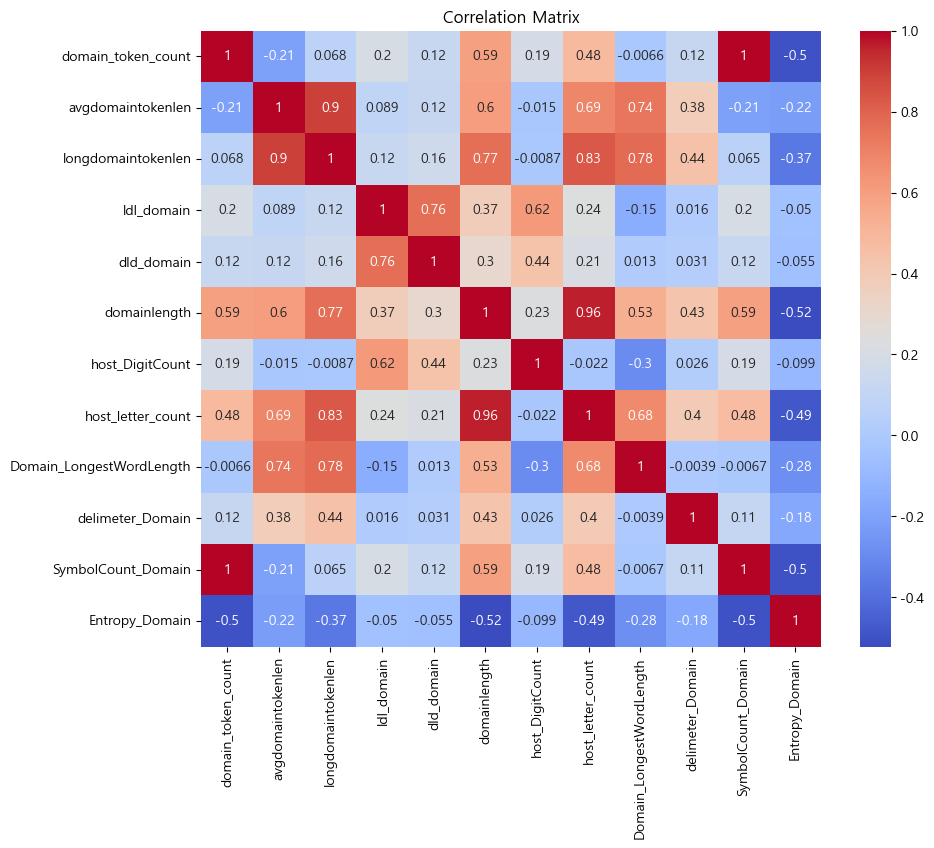

In [11]:
# 상관계수 계산
corr_matrix = select_df[corr_col].corr()  # 피어슨 상관계수

# 시각화 
plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm')
plt.title("Correlation Matrix")
plt.show()

##### >> 상관계수가 너무 큰 컬럼들은 둘 중 하나 제거 해줌

In [13]:
# 최종적으로 선택한 컬럼들
select_col = [
     'ldl_domain', 'dld_domain',
    'host_DigitCount', 'host_letter_count', 'Domain_LongestWordLength','delimeter_Domain', 
    'SymbolCount_Domain', 'Entropy_Domain',
    'URL_Type_obf_Type'
]

In [14]:
select_df = df[domain_col]

In [15]:
select_df

,domain_token_count,avgdomaintokenlen,longdomaintokenlen,ldl_domain,dld_domain,domainlength,host_DigitCount,host_letter_count,Domain_LongestWordLength,delimeter_Domain,SymbolCount_Domain,Entropy_Domain,URL_Type_obf_Type
0,4,5.500000,14,0,0,25,0,22,14,0,3,0.784493,Defacement
1,4,5.500000,14,0,0,25,0,22,14,0,3,0.784493,Defacement
2,4,5.500000,14,0,0,25,0,22,14,0,3,0.784493,Defacement
3,4,5.500000,14,0,0,25,0,22,14,0,3,0.784493,Defacement
4,4,5.500000,14,0,0,25,0,22,14,0,3,0.784493,Defacement
...,...,...,...,...,...,...,...,...,...,...,...,...,...
36702,4,5.750000,12,0,0,26,0,23,12,0,3,0.791265,spam
36703,4,3.750000,8,0,0,18,0,15,8,0,3,0.820010,spam
36704,3,6.666666,16,0,0,22,0,20,16,0,2,0.801139,spam
36705,3,4.333334,9,0,0,15,0,13,9,0,2,0.897617,spam


In [16]:
# y 값들 개수 확인 (편향되어 있는지 아닌지 확인)
select_df['URL_Type_obf_Type'].value_counts()

URL_Type_obf_Type
Defacement    7930
benign        7781
phishing      7586
malware       6712
spam          6698
Name: count, dtype: int64

In [17]:
# 악성 URL의 공격 유형 분류를 위해 정상을 나타내는 benign 행들은 삭제
cleaned_df = select_df[select_df['URL_Type_obf_Type'] != 'benign']

In [18]:
# 잘 제거되었는지 확인
cleaned_df

,domain_token_count,avgdomaintokenlen,longdomaintokenlen,ldl_domain,dld_domain,domainlength,host_DigitCount,host_letter_count,Domain_LongestWordLength,delimeter_Domain,SymbolCount_Domain,Entropy_Domain,URL_Type_obf_Type
0,4,5.500000,14,0,0,25,0,22,14,0,3,0.784493,Defacement
1,4,5.500000,14,0,0,25,0,22,14,0,3,0.784493,Defacement
2,4,5.500000,14,0,0,25,0,22,14,0,3,0.784493,Defacement
3,4,5.500000,14,0,0,25,0,22,14,0,3,0.784493,Defacement
4,4,5.500000,14,0,0,25,0,22,14,0,3,0.784493,Defacement
...,...,...,...,...,...,...,...,...,...,...,...,...,...
36702,4,5.750000,12,0,0,26,0,23,12,0,3,0.791265,spam
36703,4,3.750000,8,0,0,18,0,15,8,0,3,0.820010,spam
36704,3,6.666666,16,0,0,22,0,20,16,0,2,0.801139,spam
36705,3,4.333334,9,0,0,15,0,13,9,0,2,0.897617,spam


In [19]:
cleaned_df['URL_Type_obf_Type'].value_counts()

URL_Type_obf_Type
Defacement    7930
phishing      7586
malware       6712
spam          6698
Name: count, dtype: int64

URL_Type_obf_Type 분포 확인


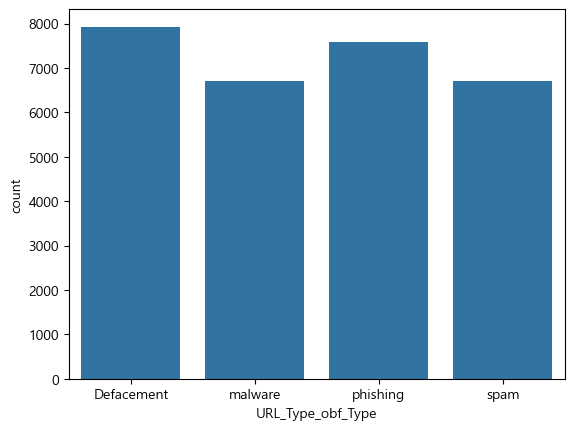

In [20]:
# 클래스 분포 확인
sns.countplot(x = cleaned_df['URL_Type_obf_Type'], data = df)
print("URL_Type_obf_Type 분포 확인")

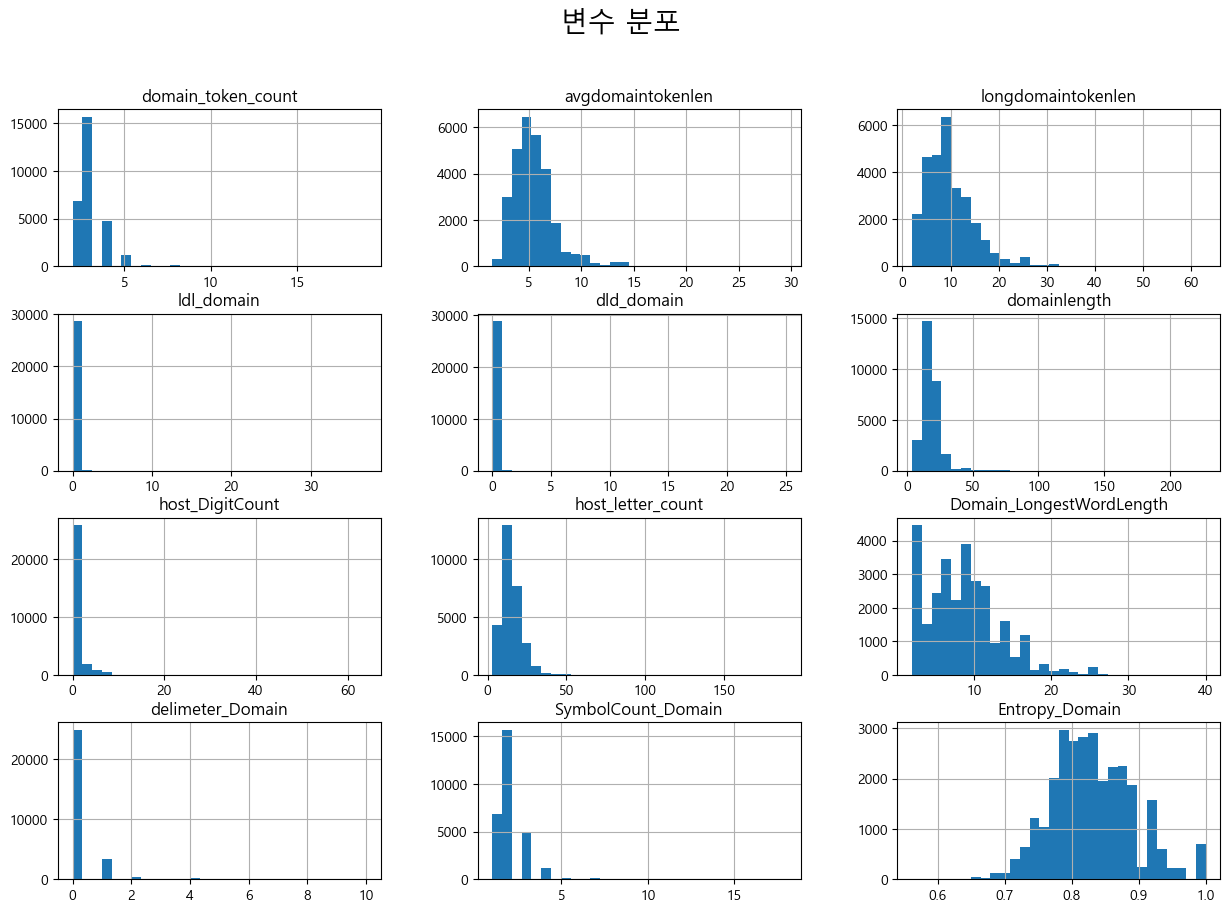

In [21]:
# 주요 feature 분포 확인
cleaned_df.hist(bins=30, figsize=(15, 10))
plt.suptitle("변수 분포", fontsize=20)
plt.show()

In [22]:
cleaned_df.columns

Index(['domain_token_count', 'avgdomaintokenlen', 'longdomaintokenlen',
       'ldl_domain', 'dld_domain', 'domainlength', 'host_DigitCount',
       'host_letter_count', 'Domain_LongestWordLength', 'delimeter_Domain',
       'SymbolCount_Domain', 'Entropy_Domain', 'URL_Type_obf_Type'],
      dtype='object')

In [23]:
# 값이 하나처럼 보인는 곳 정말 값이 하나인지 확인
cleaned_df['ldl_domain'].unique()

array([ 0,  1,  2, 37, 24, 30, 28, 21, 36,  4,  9, 14,  5,  3, 10, 12,  8,
       16,  7,  6], dtype=int64)

In [24]:
cleaned_df['dld_domain'].unique()

array([ 0,  1, 21,  4,  8,  5,  3, 25, 10,  2,  9,  6], dtype=int64)

### Modeling

### 1. Decision Tree

In [27]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, RocCurveDisplay

In [28]:
# 사용할 feature 리스트
selected_features = [
    'ldl_domain', 'dld_domain', 'host_DigitCount', 'host_letter_count', 'Domain_LongestWordLength', 
    'delimeter_Domain', 'SymbolCount_Domain', 'Entropy_Domain']

In [29]:
# X, y 설정
X = cleaned_df[selected_features]
y = cleaned_df['URL_Type_obf_Type']

In [30]:
# 표준화 하기
scaler = StandardScaler()
X_scaler = scaler.fit_transform(X)

In [31]:
# Train셋과 Test셋 분할
X_train, X_test, y_train, y_test = train_test_split(X_scaler, y, test_size=0.2, random_state=42)

In [32]:
# Decision Tree 모델 학습
model = DecisionTreeClassifier(
    max_depth=20,           
    min_samples_leaf=5,     
    random_state=42
)

model.fit(X_train, y_train)

DecisionTreeClassifier(max_depth=20, min_samples_leaf=5, random_state=42)

In [33]:
# 예측 및 평가
y_pred = model.predict(X_test)

In [34]:
print("📌 [Confusion Matrix]")
print(confusion_matrix(y_test, y_pred))
print("\n📌 [Classification Report]")
print(classification_report(y_test, y_pred))

📌 [Confusion Matrix]
[[1447   66   29    0]
 [  38 1230  132    7]
 [ 120  136 1230   29]
 [   5    1   13 1303]]

📌 [Classification Report]
              precision    recall  f1-score   support

  Defacement       0.90      0.94      0.92      1542
     malware       0.86      0.87      0.87      1407
    phishing       0.88      0.81      0.84      1515
        spam       0.97      0.99      0.98      1322

    accuracy                           0.90      5786
   macro avg       0.90      0.90      0.90      5786
weighted avg       0.90      0.90      0.90      5786



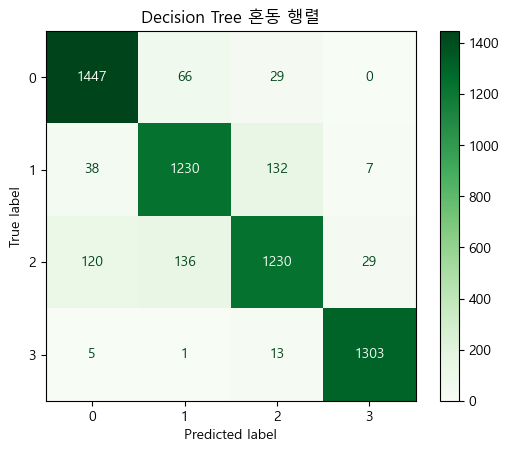

In [35]:
# 혼동행렬 시각화
from sklearn.metrics import ConfusionMatrixDisplay

# 혼동 행렬 계산
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm)

# 시각화
disp.plot(cmap='Greens') # 색상 초록계열로 설정
plt.title("Decision Tree 혼동 행렬") # title 설정
plt.show() # 시각화하기

📊 Feature Importances:

                 Feature  Importance
          Entropy_Domain       0.369
       host_letter_count       0.217
Domain_LongestWordLength       0.178
      SymbolCount_Domain       0.128
         host_DigitCount       0.067
        delimeter_Domain       0.030
              ldl_domain       0.012
              dld_domain       0.000


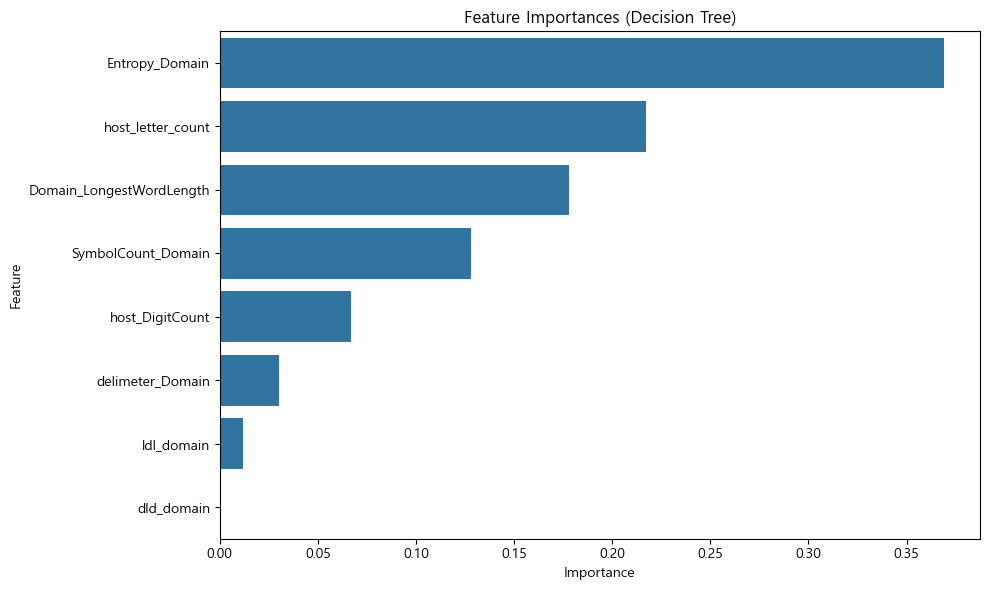

In [36]:
# Decision Tree 변수 중요도 분석
importances = model.feature_importances_
feature_names = X.columns

# 중요도 테이블 생성 (소수점 3자리)
importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
})
importance_df['Importance'] = importance_df['Importance'].round(3)

# 중요도 순 정렬
importance_df = importance_df.sort_values(by='Importance', ascending=False)

# 숫자 값 출력
print("📊 Feature Importances:\n")
print(importance_df.head(10).to_string(index=False))

# 시각화
plt.figure(figsize=(10, 6))
sns.barplot(x='Importance', y='Feature', data=importance_df)  
plt.title('Feature Importances (Decision Tree)')
plt.tight_layout()
plt.show()

In [37]:
# 변수만 사용해서 근사 함수식 만들기
features = importance_df

# 변수명과 중요도 가중치 리스트 만들기
terms = []
for i, row in features.iterrows():
    # 변수명과 중요도(소수점 3자리)
    terms.append(f"{row['Importance']:.3f}*{row['Feature']}")

# 절편(intercept) 없으면 0으로 두거나, 모델 절편값 넣기
intercept = 0  

# 식 합치기
formula = f"y ≈ {intercept} + " + " + ".join(terms)

print("📈 Decision Tree y=f(X):")
print(formula)


📈 Decision Tree y=f(X):
y ≈ 0 + 0.369*Entropy_Domain + 0.217*host_letter_count + 0.178*Domain_LongestWordLength + 0.128*SymbolCount_Domain + 0.067*host_DigitCount + 0.030*delimeter_Domain + 0.012*ldl_domain + 0.000*dld_domain


### 2. RandomForest Classifier

In [39]:
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

In [40]:
# RandomForestClassifier
rfm= RandomForestClassifier(random_state=42,
                            max_depth=20)
rfm.fit(X_train, y_train)

RandomForestClassifier(max_depth=20, random_state=42)

In [41]:
# test 셋 결과 예측
y_pred = rfm.predict(X_test)

In [42]:
# 정확도 확인
acc = accuracy_score(y_test, y_pred)

In [43]:
print("📌 [Confusion Matrix]")
print(confusion_matrix(y_test, y_pred))
print("\n📌 [Classification Report]")
print(classification_report(y_test, y_pred))

📌 [Confusion Matrix]
[[1460   64   18    0]
 [  27 1284   92    4]
 [  75   93 1333   14]
 [   1    1    5 1315]]

📌 [Classification Report]
              precision    recall  f1-score   support

  Defacement       0.93      0.95      0.94      1542
     malware       0.89      0.91      0.90      1407
    phishing       0.92      0.88      0.90      1515
        spam       0.99      0.99      0.99      1322

    accuracy                           0.93      5786
   macro avg       0.93      0.93      0.93      5786
weighted avg       0.93      0.93      0.93      5786



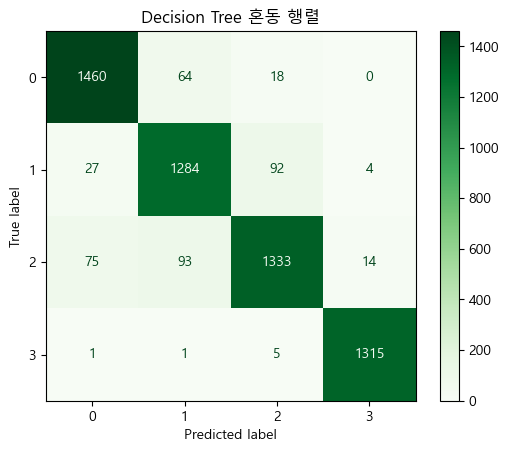

In [44]:
# 혼동행렬 시각화

# 혼동 행렬 계산
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm)

# 시각화
disp.plot(cmap='Greens') # 색상 초록계열로 설정
plt.title("Decision Tree 혼동 행렬") # title 설정
plt.grid(False)
plt.show() # 시각화하기

📊 Feature Importances :

                 Feature  Importance
          Entropy_Domain       0.351
       host_letter_count       0.216
Domain_LongestWordLength       0.207
      SymbolCount_Domain       0.111
         host_DigitCount       0.066
        delimeter_Domain       0.032
              ldl_domain       0.018
              dld_domain       0.000


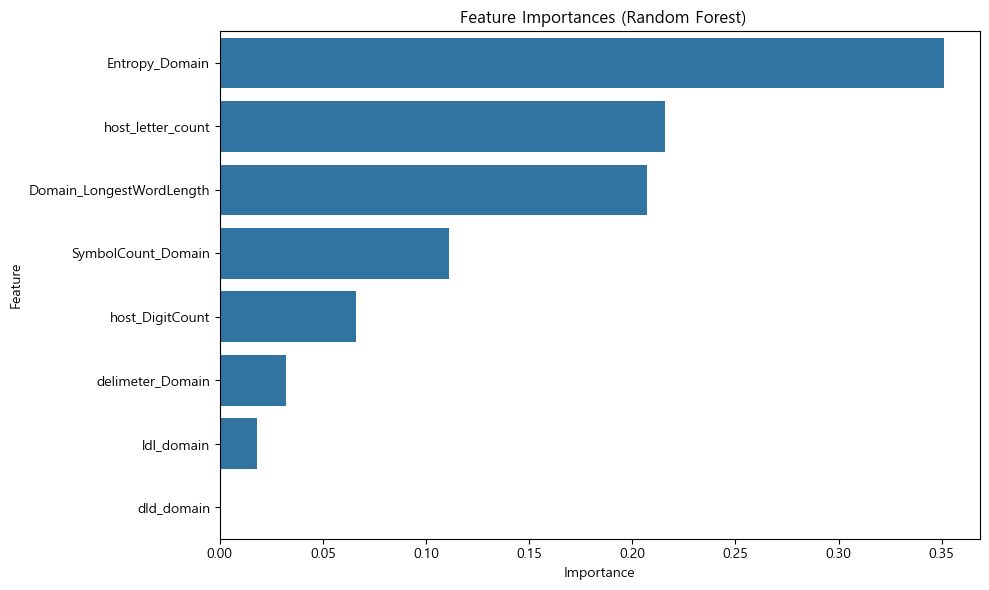

In [45]:
# 랜덤 포레스트 변수 중요도 분석
importances =rfm.feature_importances_
feature_names = X.columns

# 중요도 테이블 생성 (소수점 3자리)
importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
})
importance_df['Importance'] = importance_df['Importance'].round(3)

# 중요도 순 정렬
importance_df = importance_df.sort_values(by='Importance', ascending=False)

# 숫자 값 출력
print("📊 Feature Importances :\n")
print(importance_df.head(10).to_string(index=False))

# 시각화
plt.figure(figsize=(10, 6))
sns.barplot(x='Importance', y='Feature', data=importance_df) 
plt.title(' Feature Importances (Random Forest)')
plt.tight_layout()
plt.show()


In [46]:
# 중요 변수만 사용해서 근사 함수식 만들기
features = importance_df

# 변수명과 중요도 가중치 리스트 만들기
terms = []
for i, row in features.iterrows():
    # 변수명과 중요도(소수점 3자리)
    terms.append(f"{row['Importance']:.3f}*{row['Feature']}")

# 절편(intercept) 없으면 0으로 두거나, 모델 절편값 넣기
intercept = 0  

# 식 합치기
formula = f"y ≈ {intercept} + " + " + ".join(terms)

print("📈 RandomForest y=f(X):")
print(formula)


📈 RandomForest y=f(X):
y ≈ 0 + 0.351*Entropy_Domain + 0.216*host_letter_count + 0.207*Domain_LongestWordLength + 0.111*SymbolCount_Domain + 0.066*host_DigitCount + 0.032*delimeter_Domain + 0.018*ldl_domain + 0.000*dld_domain


### class 별 중요도 확인

In [48]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import f1_score, make_scorer
import pandas as pd

# 클래스 이름 목록
class_names = ['Defacement', 'malware', 'phishing', 'spam']

# scoring 함수 (이진 분류이므로 pos_label=1로 f1-score)
f1_scorer = make_scorer(f1_score, pos_label=1)

# 결과 저장
results = {'DecisionTree': {}, 'RandomForest': {}}

# 각 클래스에 대해 1 vs rest 이진 분류
for class_label in class_names:
    print(f"\n▶ 클래스: {class_label}")

    # 이진 타겟 만들기
    y_binary = (y == class_label).astype(int)

    # 1. Decision Tree
    dt_model = DecisionTreeClassifier(random_state=42,
                                     max_depth=20,
                                    min_samples_leaf=5)
    dt_model.fit(X_scaler, y_binary)

    dt_result = permutation_importance(
        dt_model, X_scaler, y_binary, n_repeats=10, random_state=42, scoring=f1_scorer
    )
    dt_importance = pd.DataFrame({
        'Feature': X.columns,
        'Importance': dt_result.importances_mean
    }).sort_values(by='Importance', ascending=False).head(10)
    results['DecisionTree'][class_label] = dt_importance

    print("\n[Decision Tree]")
    print(dt_importance.to_string(index=False))

    # 2. Random Forest
    rf_model = RandomForestClassifier(random_state=42,
                                     max_depth=20)
    rf_model.fit(X_scaler, y_binary)

    rf_result = permutation_importance(
        rf_model, X_scaler, y_binary, n_repeats=10, random_state=42, scoring=f1_scorer
    )
    rf_importance = pd.DataFrame({
        'Feature': X.columns,
        'Importance': rf_result.importances_mean
    }).sort_values(by='Importance', ascending=False).head(10)
    results['RandomForest'][class_label] = rf_importance

    print("\n[Random Forest]")
    print(rf_importance.to_string(index=False))



▶ 클래스: Defacement

[Decision Tree]
                 Feature  Importance
          Entropy_Domain    0.651920
       host_letter_count    0.546580
Domain_LongestWordLength    0.502376
      SymbolCount_Domain    0.194073
        delimeter_Domain    0.183059
         host_DigitCount    0.109956
              ldl_domain    0.001688
              dld_domain    0.000000

[Random Forest]
                 Feature  Importance
       host_letter_count    0.708175
          Entropy_Domain    0.703926
Domain_LongestWordLength    0.649650
      SymbolCount_Domain    0.379118
        delimeter_Domain    0.192808
         host_DigitCount    0.131160
              ldl_domain    0.018762
              dld_domain    0.000199

▶ 클래스: malware

[Decision Tree]
                 Feature  Importance
          Entropy_Domain    0.514261
       host_letter_count    0.319899
Domain_LongestWordLength    0.286759
      SymbolCount_Domain    0.283479
         host_DigitCount    0.242973
        delimeter_Domain  

In [50]:
import matplotlib.font_manager as fm

# 윈도우 한글 폰트 지정
plt.rcParams['font.family'] = 'Malgun Gothic'  # '맑은 고딕'

# 마이너스 깨짐 방지
plt.rcParams['axes.unicode_minus'] = False

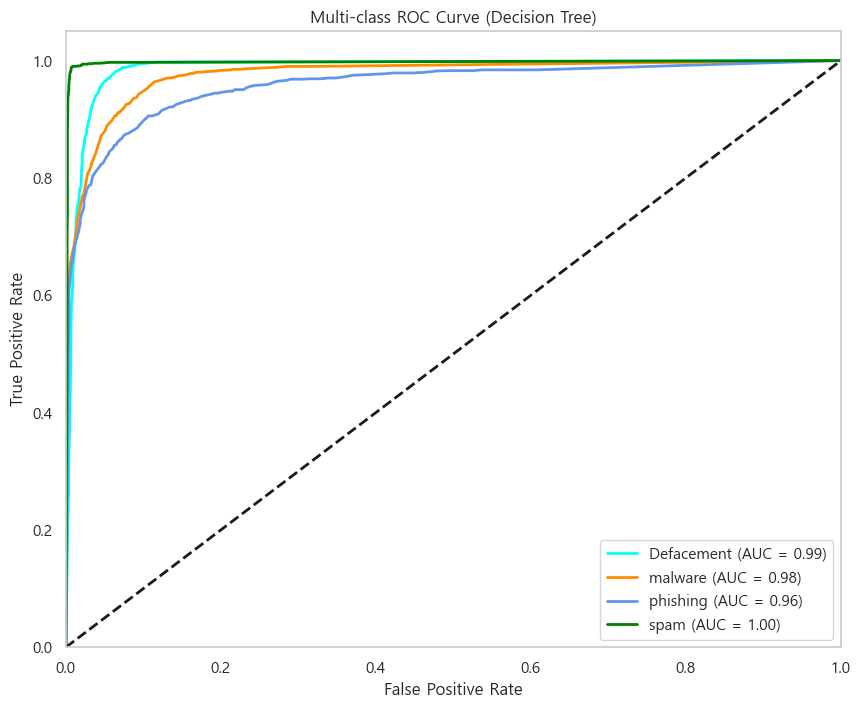

In [109]:
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt
from itertools import cycle
import numpy as np

# 클래스명
class_names = ['Defacement', 'malware', 'phishing', 'spam']
n_classes = len(class_names)

# y class를 숫자로 변환
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
le.fit(class_names)
y_test_num = le.transform(y_test)
y_test_bin = label_binarize(y_test_num, classes=range(n_classes))

# Decision Tree 모델의 확률 예측값
y_score = model.predict_proba(X_test)

# ROC 계산
fpr = dict()
tpr = dict()
roc_auc = dict()

for i in range(n_classes):
    fpr[i], tpr[i], _ = roc_curve(y_test_bin[:, i], y_score[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

# 시각화
colors = cycle(['aqua', 'darkorange', 'cornflowerblue', 'green'])
plt.figure(figsize=(10, 8))

for i, color in zip(range(n_classes), colors):
    plt.plot(fpr[i], tpr[i], color=color, lw=2,
             label=f'{class_names[i]} (AUC = {roc_auc[i]:.2f})')

plt.plot([0, 1], [0, 1], 'k--', lw=2)
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Multi-class ROC Curve (Decision Tree)')
plt.legend(loc='lower right')
plt.grid()
plt.show()


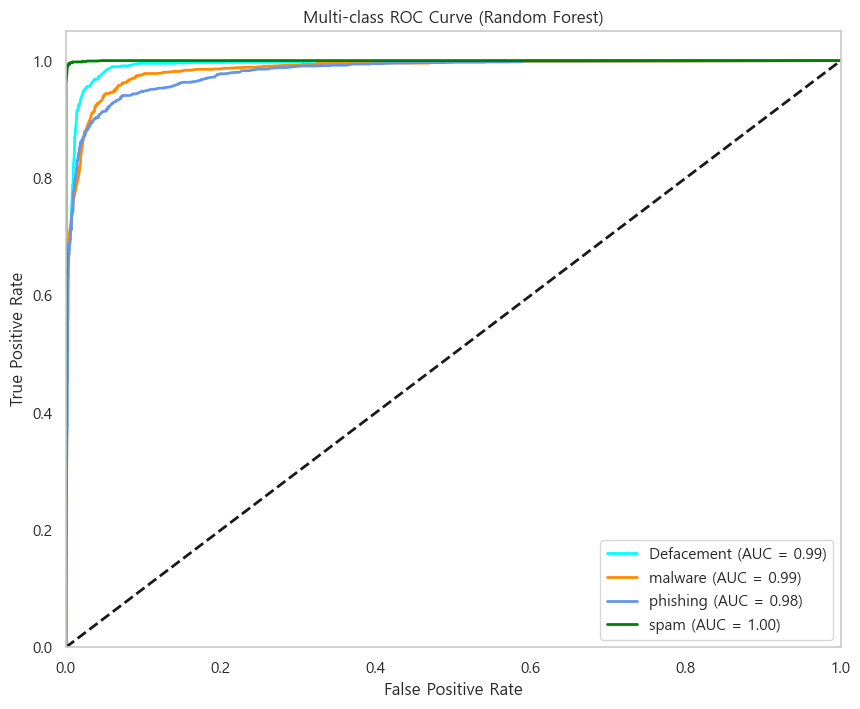

In [110]:
# Random Forest 모델의 확률 예측값
y_score = rfm.predict_proba(X_test)

# ROC 계산
fpr = dict()
tpr = dict()
roc_auc = dict()

for i in range(n_classes):
    fpr[i], tpr[i], _ = roc_curve(y_test_bin[:, i], y_score[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

# 시각화
colors = cycle(['aqua', 'darkorange', 'cornflowerblue', 'green'])
plt.figure(figsize=(10, 8))

for i, color in zip(range(n_classes), colors):
    plt.plot(fpr[i], tpr[i], color=color, lw=2,
             label=f'{class_names[i]} (AUC = {roc_auc[i]:.2f})')

plt.plot([0, 1], [0, 1], 'k--', lw=2)
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Multi-class ROC Curve (Random Forest)')
plt.legend(loc='lower right')
plt.grid()
plt.show()
